# Smoking is bad

In [ ]:
# TODO: install all the necessary packages


from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [ ]:
# TODO: load the data using the pathlib library to create the path to your data

# Step 1: Construct the path to the CSV file
data_path = Path("data") / "smoking_data.csv"

# Step 2: Check that Python can find the file
print(data_path.exists())

# Step 3: Read the CSV into a Pandas DataFrame
df = pd.read_csv(data_path)

# Step 4: Display the first five observations
df.head()


In [ ]:
# TODO: what are the dimensions of the data frame?

df.shape

In [ ]:
# TODO: use .describe() on your data frame: what do you notice about the string columns?

df.describe(include='all')

In [ ]:
# TODO: do not forget to check the null values

df.isna().sum()

In [ ]:
# TODO: prepare your data frame so that you can work with

df_clean = df.drop(columns=["Unnamed: 0"]).copy()

print(df_clean["outcome"].unique())
print(df_clean["smoker"].unique())

df_clean["alive"] = df_clean["outcome"].map({
    "Alive": 1,
    "Dead": 0
})

df_clean["smokes"] = df_clean["smoker"].map({
    "Yes": 1,
    "No": 0
})

df_clean[["outcome", "alive", "smoker", "smokes"]].head(10)

## Smoking analysis
Let's first check what your cousin did.

In [ ]:
# TODO: Reimplement the small code snippet described in the problem set instructions.

df.groupby("smoker").agg(
    prob=("outcome", lambda x: (x == "Alive").mean()),
    survivors=("outcome", lambda x: (x == "Alive").sum()),
    total=("outcome", "count")
)

You should get the same results.

# Is smoking really good?
Now it is up to you to run the analysis further and check what could be underlying your cousings results.


## 1. Investigating Age as a Potential Confounder

The initial analysis shows that smokers have a higher observed survival probability (76.1%) than nonsmokers (68.6%).

However, this unconditional relationship may be driven by differences in the characteristics of smokers and nonsmokers.

**Hypothesis:** Age may be a confounding variable because it is related to survival and may also differ across smoking groups.

We investigate this by:
1. Comparing age distributions between smokers and nonsmokers.
2. Examining the age composition of each smoking group.
3. Comparing survival probabilities within age groups.

In [41]:

# Summary statistics for age by smoking status
age_summary = (
    df.groupby("smoker")
    .agg(
        mean_age=("age", "mean"),
        median_age=("age", "median"),
        std_age=("age", "std"),
        n=("age", "count")
    )
)

age_summary.round(2)


,mean_age,median_age,std_age,n
smoker,,,,
No,48.70,48.0,18.79,732
Yes,44.68,45.0,15.28,582


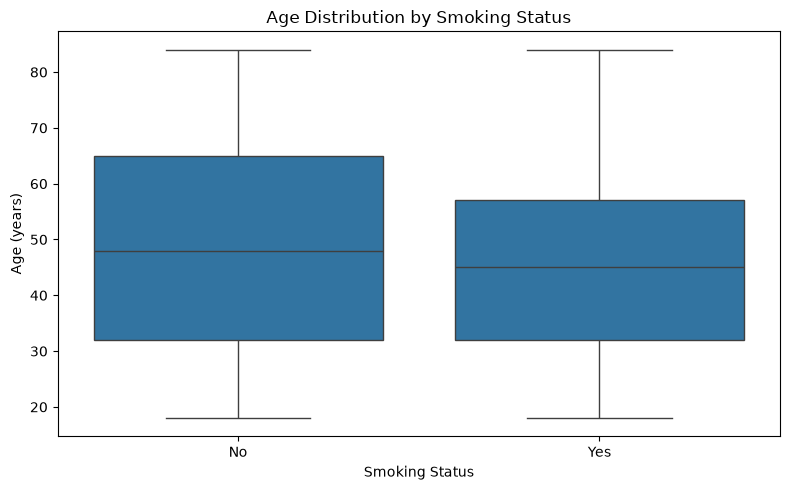

In [42]:
# Compare age distributions by smoking status
fig, ax = plt.subplots(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="smoker",
    y="age",
    order=["No", "Yes"],
    ax=ax
)

ax.set_title("Age Distribution by Smoking Status")
ax.set_xlabel("Smoking Status")
ax.set_ylabel("Age (years)")

plt.tight_layout()
plt.show()



### Interpretation: Age Differences

The descriptive statistics and boxplot indicate that [describe how smokers and nonsmokers differ in age].

This is relevant because survival probabilities may vary with age. Therefore, differences in age composition could contribute to the observed survival advantage among smokers.

To investigate this further, we compare survival probabilities within age groups.

In [43]:

# Create age categories
df_age = df.copy()

df_age["age_group"] = pd.cut(
    df_age["age"],
    bins=[17, 35, 50, 65, 85],
    labels=["18-35", "36-50", "51-65", "66-85"]
)

# Calculate age-group shares within each smoking category
age_composition = pd.crosstab(
    df_age["age_group"],
    df_age["smoker"],
    normalize="columns"
)

(age_composition * 100).round(1)

smoker,No,Yes
age_group,,
18-35,33.2,32.1
36-50,19.0,31.3
51-65,23.2,28.2
66-85,24.6,8.4


In [44]:

# Calculate survival by age group and smoking status
age_survival = (
    df_age.groupby(
        ["age_group", "smoker"],
        observed=True
    )
    .agg(
        survival_rate=(
            "outcome",
            lambda x: (x == "Alive").mean()
        ),
        n=("outcome", "count")
    )
    .reset_index()
)

age_survival.round(3)


,age_group,smoker,survival_rate,n
0,18-35,No,0.971,243
1,18-35,Yes,0.973,187
2,36-50,No,0.906,139
3,36-50,Yes,0.852,182
4,51-65,No,0.676,170
5,51-65,Yes,0.610,164
6,66-85,No,0.139,180
7,66-85,Yes,0.122,49


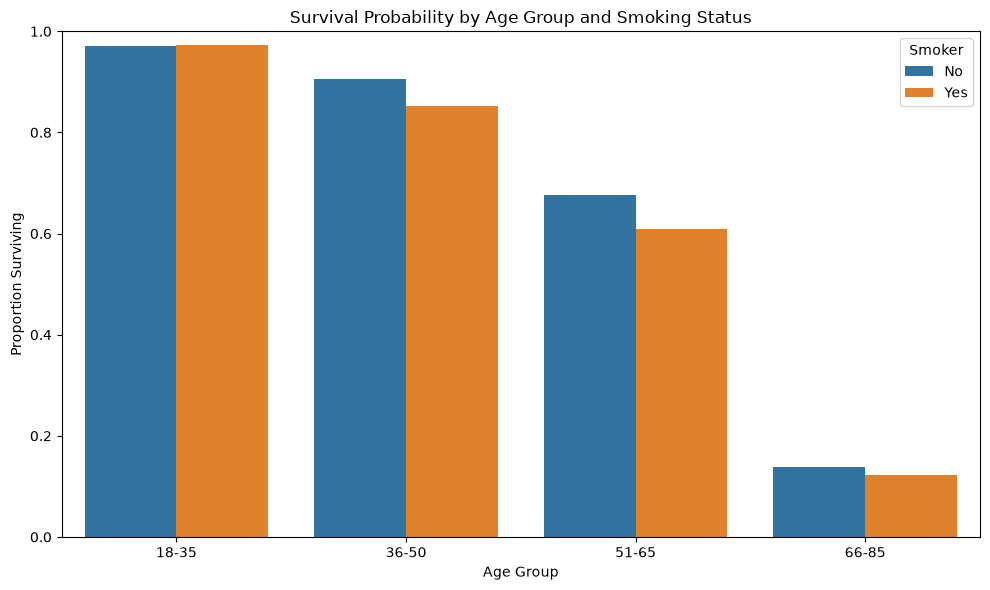

In [45]:

# Compare survival rates within age groups
fig, ax = plt.subplots(figsize=(10, 6))

sns.barplot(
    data=age_survival,
    x="age_group",
    y="survival_rate",
    hue="smoker",
    hue_order=["No", "Yes"],
    errorbar=None,
    ax=ax
)

ax.set_title("Survival Probability by Age Group and Smoking Status")
ax.set_xlabel("Age Group")
ax.set_ylabel("Proportion Surviving")
ax.set_ylim(0, 1)
ax.legend(title="Smoker")

plt.tight_layout()
plt.show()


### Conclusion: Does Smoking Increase Survival?

The initial unconditional analysis suggested that smokers have a higher survival probability (76.1%) than nonsmokers (68.6%), a difference of approximately 7.5 percentage points. However, our age-adjusted comparisons suggest that this relationship is largely driven by differences in the age composition of the two groups.

**Key findings:**

1. **Age composition differs substantially:** Approximately 24.6% of nonsmokers are aged 66–85, compared with only 8.4% of smokers. Since survival probabilities decline sharply with age, the greater concentration of elderly individuals among nonsmokers reduces their overall survival rate.

2. **The relationship largely reverses within age groups:** Nonsmokers have higher survival probabilities in three of the four age groups:
   - Ages 36–50: 90.6% versus 85.2% for smokers.
   - Ages 51–65: 67.6% versus 61.0% for smokers.
   - Ages 66–85: 13.9% versus 12.2% for smokers.

   Among individuals aged 18–35, survival rates are almost identical (97.1% for nonsmokers versus 97.3% for smokers).

3. **Evidence of confounding:** These results illustrate a Simpson's-paradox-like pattern, where the positive aggregate association between smoking and survival largely disappears or reverses when conditioning on age. The unconditional comparison is misleading because smokers and nonsmokers have different age distributions.

**Overall conclusion:** Our analysis does not support the claim that smoking increases survival. Instead, age composition provides a plausible explanation for smokers' apparently higher overall survival rates. However, these are observational comparisons, and other confounding variables may remain. Therefore, the results should not be interpreted as definitive estimates of smoking's causal effect on survival.